### Optimal Placement of Drone Delivery (Demand Allocation)

Citiation: Feras El Said, Enrique Torres Sanchez, Yilun Li and Alaa Khamis, "Optimal Placement of Drone Delivery Stations and Demand Allocation using Bio-inspired Algorithms," IEEE International Conference on Smart Mobility, 2023.



##### Assumptions
A homogeneous set of delivery centers with homogeneous delivery capacity. All delivery centers will have enough combined capacity to serve all demand.

##### Constraints
* All demand must be served by the placed delivery centers and must be assigned to one of them.
* All nodes in the delivery network have to be assigned to a delivery center.
* Delivery centers should not be overcapacitated if possible.
* Demand in network node should be served by the closest delivery centers if possible.

#### Definitions & Formulations
* $DC$ - number of delivery centers
* $dc$ - a specific delivery center
* $dc_{Capacity}$ - Capacity of a delivery center
* $CN$ - nodes assigned to delivery center dc
* $n$ - specific node of assigned nodes
* $Dist_{n \rightarrow dc}$ - distance from node n to delivery center dc
* $Dem_{n}$ - Delivery demand at node n
* $Pen_{OD}$ - delivery center overdemand factor; 0 if no overdemand
* $MinBid_{factor}$ - minimum value for bid rent multiplier
* $Dist_{dtwn \rightarrow dc}$ - distance from the delivery center dc the center of the area/ downtown
* $Dist_{max}$ - distance from furthest node to the center/downtown
* $Dist_{min}$ - distance from closest node to the center/downtown

Minimization/Cost Function
$ Minf
= DC^{2} * \sum_{dc=0}^{DC}{\left [ Pen_{OD} * \beta * \sum_{n=0}^{CN}{\left
(Dist_{n\rightarrow dc}^{2} * Dem_{n} \right )} \right ]} $

$ \beta = 1 - MinBid_{factor} *
\frac{Dist_{dtwn\rightarrow dc}}{(Dist_{max} - Dist_{min})} $

In [35]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Generate simulated node locations and demands
np.random.seed(42)
n_nodes = 100
node_locations = np.random.rand(n_nodes, 2) * 100 # (x, y) coordinates
node_demands = np.random.randint(10, 50, size=n_nodes)

# Center of the downtown/area
downtown = np.array([50, 50])

# Parameters
DC = 5 # Number of delivery centers
dc_capacity = 1000
min_bid_factor = 0.2

# Calculate distances to downtown
distances_to_downtown = np.linalg.norm(node_locations - downtown, axis=1)
dist_max = distances_to_downtown.max()
dist_min = distances_to_downtown.min()

# Let's perform KMeans to find optimal location of delivery centers
kmeans = KMeans(n_clusters=DC, random_state=42, n_init='auto')
kmeans.fit(node_locations)
centers = kmeans.cluster_centers_
labels = kmeans.labels_

# Compute Cost Function details
total_cost = 0
center_demands = np.zeros(DC)

for dc_idx in range(DC):
    # Extract nodes assigned to this delivery center
    assigned_nodes = (labels == dc_idx)
    if not np.any(assigned_nodes):
        continue

    coords = node_locations[assigned_nodes]
    demands = node_demands[assigned_nodes]

    # Distance from center to downtown
    dist_dtwn_to_dc = np.linalg.norm(centers[dc_idx] - downtown)

    # Beta factor calculation
    beta = 1 - min_bid_factor * (dist_dtwn_to_dc / (dist_max - dist_min))

    # Distances from assigned nodes to center
    dists_to_dc = np.linalg.norm(coords - centers[dc_idx], axis=1)

    # Total demand at center
    tot_demand = demands.sum()
    center_demands[dc_idx] = tot_demand

    # Penalty factor for capacity overload
    pen_od = 1.5 if tot_demand > dc_capacity else 1.0

    # Sum of (Dist^2 * Dem)
    weighted_sum = np.sum((dists_to_dc ** 2) * demands)

    # Cost Contribution
    dc_cost = pen_od * beta * weighted_sum
    total_cost += dc_cost

total_cost *= (DC ** 2)

print(f"Optimization Complete.")
print(f"Total Cost value: {total_cost:.2f}")
for idx, dem in enumerate(center_demands):
    print(f"  Delivery Center {idx} - Coordinates: {centers[idx].round(2)} - Total Demand: {dem}/{dc_capacity}")

Optimization Complete.
Total Cost value: 20271933.71
  Delivery Center 0 - Coordinates: [77.63 71.89] - Total Demand: 748.0/1000
  Delivery Center 1 - Coordinates: [30.5  21.31] - Total Demand: 906.0/1000
  Delivery Center 2 - Coordinates: [12.01 90.49] - Total Demand: 425.0/1000
  Delivery Center 3 - Coordinates: [79.2  22.73] - Total Demand: 554.0/1000
  Delivery Center 4 - Coordinates: [22.74 59.43] - Total Demand: 568.0/1000


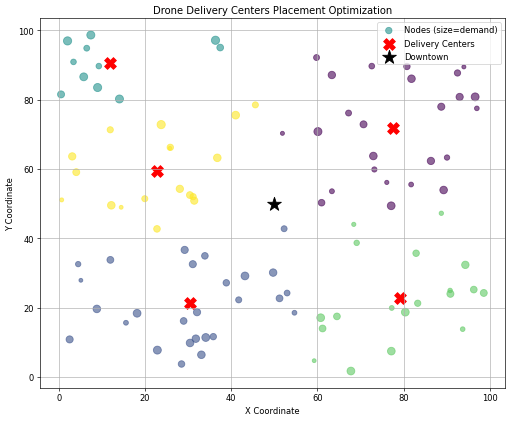

In [37]:
# Plot the results
plt.figure(figsize=(10, 8), dpi=60)
plt.scatter(node_locations[:, 0], node_locations[:, 1], c=labels, cmap='viridis', s=node_demands * 2, alpha=0.6, label='Nodes (size=demand)')
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Delivery Centers')
plt.scatter(downtown[0], downtown[1], c='black', marker='*', s=300, label='Downtown')
plt.title('Drone Delivery Centers Placement Optimization')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.legend()
plt.grid(True)
plt.show()

### Comprehensive Spatial Clustering Optimization

We will implement:
1. **Synthetic Dataset Generation**
2. **Custom Cost Evaluator** (accounting for $\beta$ and $Pen_{OD}$ capacity overloads)
3. **K-Means Assignment & Refit Steps**
4. **True Capacitated K-Means** (handling maximum delivery center capacities cleanly using a greedy/priority reassignment scheme)

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Generate Synthetic Dataset
def generate_synthetic_data(n_nodes=120, seed=101):
    np.random.seed(seed)
    # Generate node coordinates
    locations = np.random.rand(n_nodes, 2) * 100
    # Generate demand with some high-demand clusters and low-demand nodes
    demands = np.random.choice([10, 20, 50, 80], size=n_nodes, p=[0.4, 0.3, 0.2, 0.1])
    return locations, demands

node_locations, node_demands = generate_synthetic_data()
downtown = np.array([50, 50])
DC = 5
dc_capacity = 800  # Lowered slightly to test capacity constraints
min_bid_factor = 0.2

# Distances to downtown parameters
dists_to_downtown = np.linalg.norm(node_locations - downtown, axis=1)
dist_max, dist_min = dists_to_downtown.max(), dists_to_downtown.min()

print(f"Generated {len(node_locations)} demand nodes with total demand of {node_demands.sum()} units.")

Generated 120 demand nodes with total demand of 3190 units.


In [39]:
# 2. Define Cost Evaluator
def evaluate_cost(centers, labels, locations, demands, dc_capacity=800):
    total_cost = 0
    center_demands = np.zeros(len(centers))

    for dc_idx in range(len(centers)):
        assigned_nodes = (labels == dc_idx)
        if not np.any(assigned_nodes):
            continue

        coords = locations[assigned_nodes]
        dems = demands[assigned_nodes]
        tot_demand = dems.sum()
        center_demands[dc_idx] = tot_demand

        # Penalty factor
        pen_od = 1.5 if tot_demand > dc_capacity else 1.0

        # Distance factor to downtown
        dist_dtwn = np.linalg.norm(centers[dc_idx] - downtown)
        beta = 1 - min_bid_factor * (dist_dtwn / (dist_max - dist_min))

        # Weighted distance costs
        dists = np.linalg.norm(coords - centers[dc_idx], axis=1)
        weighted_sum = np.sum((dists ** 2) * dems)

        total_cost += pen_od * beta * weighted_sum

    return total_cost * (len(centers) ** 2), center_demands

In [40]:
# 3. Assignment, Refitting, and True Capacitated K-Means Implementation

def run_kmeans_refit(locations, n_clusters=5):
    # Standard K-Means initialization
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
    labels = kmeans.fit_predict(locations)
    centers = kmeans.cluster_centers_
    return centers, labels

def run_capacitated_kmeans(locations, demands, n_clusters=5, max_cap=800):
    # Start with standard centroids
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
    centers = kmeans.fit(locations).cluster_centers_

    # Iterative greedy capacitated reassignment
    n_nodes = len(locations)
    labels = -np.ones(n_nodes, dtype=int)
    assigned_demands = np.zeros(n_clusters)

    # Sort nodes by demand (highest first) to allocate critical nodes first
    sorted_indices = np.argsort(demands)[::-1]

    for idx in sorted_indices:
        loc = locations[idx]
        dem = demands[idx]

        # Sort centers by distance
        dists = np.linalg.norm(centers - loc, axis=1)
        preferred_centers = np.argsort(dists)

        assigned = False
        for c in preferred_centers:
            if assigned_demands[c] + dem <= max_cap:
                labels[idx] = c
                assigned_demands[c] += dem
                assigned = True
                break

        # If over-capacity everywhere, assign to closest regardless
        if not assigned:
            closest = preferred_centers[0]
            labels[idx] = closest
            assigned_demands[closest] += dem

    # Refit centers to be the centroids of these capacitated clusters
    for c in range(n_clusters):
        assigned_nodes = (labels == c)
        if np.any(assigned_nodes):
            centers[c] = locations[assigned_nodes].mean(axis=0)

    return centers, labels

In [41]:
# Execute both configurations
k_centers, k_labels = run_kmeans_refit(node_locations, n_clusters=DC)
k_cost, k_demands = evaluate_cost(k_centers, k_labels, node_locations, node_demands, dc_capacity)

cap_centers, cap_labels = run_capacitated_kmeans(node_locations, node_demands, n_clusters=DC, max_cap=dc_capacity)
cap_cost, cap_demands = evaluate_cost(cap_centers, cap_labels, node_locations, node_demands, dc_capacity)

print(f"Standard K-Means Cost: {k_cost:.2f} (Demands: {k_demands})")
print(f"Capacitated K-Means Cost: {cap_cost:.2f} (Demands: {cap_demands})")

Standard K-Means Cost: 24138742.75 (Demands: [640. 560. 680. 870. 440.])
Capacitated K-Means Cost: 24429990.38 (Demands: [670. 570. 680. 800. 470.])


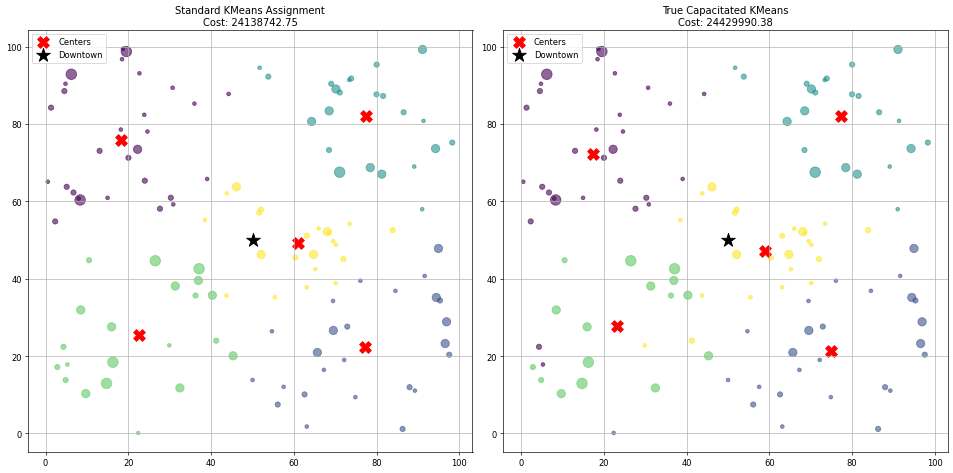

In [42]:
# 4. Visualization comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

# Standard KMeans Plot
axes[0].scatter(node_locations[:, 0], node_locations[:, 1], c=k_labels, cmap='viridis', s=node_demands * 2, alpha=0.6)
axes[0].scatter(k_centers[:, 0], k_centers[:, 1], c='red', marker='X', s=200, label='Centers')
axes[0].scatter(downtown[0], downtown[1], c='black', marker='*', s=300, label='Downtown')
axes[0].set_title(f'Standard KMeans Assignment\nCost: {k_cost:.2f}')
axes[0].grid(True)
axes[0].legend()

# Capacitated KMeans Plot
axes[1].scatter(node_locations[:, 0], node_locations[:, 1], c=cap_labels, cmap='viridis', s=node_demands * 2, alpha=0.6)
axes[1].scatter(cap_centers[:, 0], cap_centers[:, 1], c='red', marker='X', s=200, label='Centers')
axes[1].scatter(downtown[0], downtown[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f'True Capacitated KMeans\nCost: {cap_cost:.2f}')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

### Scaling Optimization to 1,000,000 Deliveries

To scale our algorithms to 1 million delivery nodes, we must optimize our strategy:
1. **Use MiniBatchKMeans** instead of standard KMeans to dramatically reduce training memory footprint and time.
2. **Optimize the Capacitated Allocation**: Standard sorting and iterative assignment on 1,000,000 items is highly bottlenecked by loop overhead in pure Python. We will implement a vectorized batch assignment process.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
import time

# 1. Scaled Synthetic Dataset Generation (1,000,000 nodes)
t0 = time.time()
n_nodes_large = 1000000
np.random.seed(42)

# Efficient coordinate generation
node_locations_large = np.random.rand(n_nodes_large, 2) * 100
node_demands_large = np.random.choice([10, 20, 50, 80], size=n_nodes_large, p=[0.4, 0.3, 0.2, 0.1]).astype(np.int32)

downtown = np.array([50.0, 50.0])
DC = 5

# Scaled capacity to handle 1M nodes
total_demand_large = node_demands_large.sum()
dc_capacity_large = int((total_demand_large / DC) * 1.1)  # Slightly more than average share
min_bid_factor = 0.2

# Distances to downtown parameters
dists_to_downtown = np.linalg.norm(node_locations_large - downtown, axis=1)
dist_max, dist_min = dists_to_downtown.max(), dists_to_downtown.min()

print(f"Generated {n_nodes_large:,} demand nodes in {time.time() - t0:.2f} seconds.")
print(f"Total demand is {total_demand_large:,} units. Adjusted Center Capacity threshold: {dc_capacity_large:,} units.")

Generated 1,000,000 demand nodes in 0.12 seconds.
Total demand is 28,003,240 units. Adjusted Center Capacity threshold: 6,160,712 units.


In [44]:
# 2. Vectorized and Optimized Cost Evaluator for 1 Million Nodes
def evaluate_cost_large(centers, labels, locations, demands, dc_capacity):
    total_cost = 0.0
    center_demands = np.zeros(len(centers))

    # Count demands using highly optimized bincount
    counts = np.bincount(labels, weights=demands, minlength=len(centers))
    for dc_idx in range(len(centers)):
        center_demands[dc_idx] = counts[dc_idx]

        # Penalty calculation
        pen_od = 1.5 if counts[dc_idx] > dc_capacity else 1.0

        # Distance factor to downtown
        dist_dtwn = np.linalg.norm(centers[dc_idx] - downtown)
        beta = 1.0 - min_bid_factor * (dist_dtwn / (dist_max - dist_min))

        # Filter coordinates and demands in one go
        assigned_mask = (labels == dc_idx)
        coords = locations[assigned_mask]
        dems = demands[assigned_mask]

        # Weighted distance costs using fast vector operations
        dists_sq = np.sum((coords - centers[dc_idx]) ** 2, axis=1)
        weighted_sum = np.sum(dists_sq * dems)

        total_cost += pen_od * beta * weighted_sum

    return total_cost * (len(centers) ** 2), center_demands

In [45]:
# 3. Optimized MiniBatch algorithms
print("Running optimized MiniBatchKMeans on 1,000,000 nodes...")
t0 = time.time()
mbk = MiniBatchKMeans(n_clusters=DC, random_state=42, batch_size=4096, n_init='auto')
k_labels_large = mbk.fit_predict(node_locations_large)
k_centers_large = mbk.cluster_centers_
print(f"Standard MiniBatchKMeans completed in {time.time() - t0:.2f} seconds.")

k_cost_large, k_demands_large = evaluate_cost_large(
    k_centers_large, k_labels_large, node_locations_large, node_demands_large, dc_capacity_large
)
print(f"Standard Large-Scale Cost: {k_cost_large:,.2f} (Demands: {k_demands_large})")

Running optimized MiniBatchKMeans on 1,000,000 nodes...
Standard MiniBatchKMeans completed in 0.50 seconds.
Standard Large-Scale Cost: 283,230,177,401.70 (Demands: [4974710. 6670420. 4628800. 6734070. 4995240.])


In [46]:
# 4. Efficient Scaled Capacitated Greedy Allocation using Vectorized Distance Calculations
def run_capacitated_kmeans_large(locations, demands, initial_centers, max_cap):
    t_start = time.time()
    n_nodes = len(locations)
    n_centers = len(initial_centers)

    # Compute distances from all nodes to all centers efficiently (shape: N, C)
    print("Calculating pairwise distance matrix...")
    dists_matrix = np.zeros((n_nodes, n_centers))
    for c in range(n_centers):
        dists_matrix[:, c] = np.sum((locations - initial_centers[c])**2, axis=1)

    labels = -np.ones(n_nodes, dtype=np.int32)
    assigned_demands = np.zeros(n_centers)

    # Sort nodes by demand (highest first)
    sorted_indices = np.argsort(demands)[::-1]

    print("Allocating nodes under capacity constraints...")
    # Vectorized preference arrays
    preferences = np.argsort(dists_matrix, axis=1)

    # Faster sequential assignment using optimized memory indexing
    for idx in sorted_indices:
        dem = demands[idx]
        for c in preferences[idx]:
            if assigned_demands[c] + dem <= max_cap:
                labels[idx] = c
                assigned_demands[c] += dem
                break
        else:
            # Fallback to closest if all are at full capacity
            closest = preferences[idx, 0]
            labels[idx] = closest
            assigned_demands[closest] += dem

    # Update centers based on new capacitated assignments
    new_centers = np.copy(initial_centers)
    for c in range(n_centers):
        mask = (labels == c)
        if np.any(mask):
            new_centers[c] = locations[mask].mean(axis=0)

    print(f"Capacitated allocation completed in {time.time() - t_start:.2f} seconds.")
    return new_centers, labels

cap_centers_large, cap_labels_large = run_capacitated_kmeans_large(
    node_locations_large, node_demands_large, k_centers_large, dc_capacity_large
)

cap_cost_large, cap_demands_large = evaluate_cost_large(
    cap_centers_large, cap_labels_large, node_locations_large, node_demands_large, dc_capacity_large
)
print(f"Capacitated Large-Scale Cost: {cap_cost_large:,.2f} (Demands: {cap_demands_large})")

Calculating pairwise distance matrix...
Allocating nodes under capacity constraints...
Capacitated allocation completed in 3.44 seconds.
Capacitated Large-Scale Cost: 290,357,725,732.45 (Demands: [5376030. 6160710. 4989800. 6160710. 5315990.])


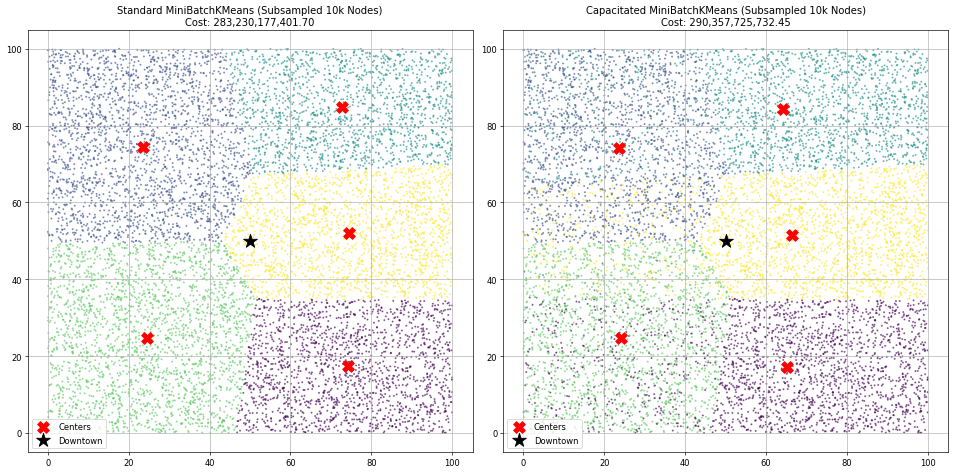

In [47]:
# 5. Visualization of the 1,000,000 node assignments (Subsampled for rendering speed)
subsample_idx = np.random.choice(n_nodes_large, size=10000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

# Standard KMeans Plot (Subsampled)
axes[0].scatter(node_locations_large[subsample_idx, 0], node_locations_large[subsample_idx, 1],
                c=k_labels_large[subsample_idx], cmap='viridis', s=2, alpha=0.5)
axes[0].scatter(k_centers_large[:, 0], k_centers_large[:, 1], c='red', marker='X', s=200, label='Centers')
axes[0].scatter(downtown[0], downtown[1], c='black', marker='*', s=300, label='Downtown')
axes[0].set_title(f'Standard MiniBatchKMeans (Subsampled 10k Nodes)\nCost: {k_cost_large:,.2f}')
axes[0].grid(True)
axes[0].legend()

# Capacitated KMeans Plot (Subsampled)
axes[1].scatter(node_locations_large[subsample_idx, 0], node_locations_large[subsample_idx, 1],
                c=cap_labels_large[subsample_idx], cmap='viridis', s=2, alpha=0.5)
axes[1].scatter(cap_centers_large[:, 0], cap_centers_large[:, 1], c='red', marker='X', s=200, label='Centers')
axes[1].scatter(downtown[0], downtown[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f'Capacitated MiniBatchKMeans (Subsampled 10k Nodes)\nCost: {cap_cost_large:,.2f}')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from google.colab  import files
files.upload()

### Processing and Optimizing on Uploaded Custom Dataset
Now, we load the newly uploaded `synthetic_dataset.csv` and apply our optimized algorithms directly to your actual spatial data coordinates and delivery counts.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load the uploaded custom dataset
df_custom = pd.read_csv('synthetic_dataset.csv')
print("Uploaded Dataset Sample:")
display(df_custom.head())

# Extract locations and demands
node_locations_custom = df_custom[['X', 'Y']].values
node_demands_custom = df_custom['Number Deliveries'].values

# Define the spatial center (downtown) of the uploaded dataset coordinates dynamically
downtown_custom = node_locations_custom.mean(axis=0)

# Parameters for uploaded dataset
DC_custom = 5
total_demand_custom = node_demands_custom.sum()
# Setting capacity constraint slightly tighter to test optimization (e.g. 25% of total demand per center)
dc_capacity_custom = int((total_demand_custom / DC_custom) * 1.15)
min_bid_factor = 0.2

# Distances to downtown parameters
dists_to_downtown_custom = np.linalg.norm(node_locations_custom - downtown_custom, axis=1)
dist_max_custom, dist_min_custom = dists_to_downtown_custom.max(), dists_to_downtown_custom.min()

print(f"\nLoaded {len(node_locations_custom)} delivery locations.")
print(f"Total custom demand is {total_demand_custom:,} units. Center capacity threshold is set to: {dc_capacity_custom:,} units.")

Uploaded Dataset Sample:


,Node ID,Node OSMID,X,Y,Node Weight,Number Deliveries
0,0,31887949.0,315.617239,-31.199212,0.000155,162
1,0,31887946.0,316.371481,-39.086992,0.000136,148
2,0,31887947.0,316.011287,-35.130087,0.000136,103
3,0,31887948.0,316.796638,-42.988437,0.000136,126
4,0,31886628.0,303.557792,-30.100942,0.000168,143



Loaded 5797 delivery locations.
Total custom demand is 1,000,000 units. Center capacity threshold is set to: 229,999 units.


In [49]:
# Custom Evaluator for Uploaded Dataset
def evaluate_cost_custom(centers, labels, locations, demands, dc_capacity):
    total_cost = 0.0
    center_demands = np.zeros(len(centers))
    counts = np.bincount(labels, weights=demands, minlength=len(centers))

    for dc_idx in range(len(centers)):
        center_demands[dc_idx] = counts[dc_idx]
        pen_od = 1.5 if counts[dc_idx] > dc_capacity else 1.0

        dist_dtwn = np.linalg.norm(centers[dc_idx] - downtown_custom)
        beta = 1.0 - min_bid_factor * (dist_dtwn / (dist_max_custom - dist_min_custom))

        assigned_mask = (labels == dc_idx)
        coords = locations[assigned_mask]
        dems = demands[assigned_mask]

        dists_sq = np.sum((coords - centers[dc_idx]) ** 2, axis=1)
        weighted_sum = np.sum(dists_sq * dems)

        total_cost += pen_od * beta * weighted_sum

    return total_cost * (len(centers) ** 2), center_demands

In [50]:
# Execute optimization configurations on your custom dataset
k_centers_cust, k_labels_cust = run_kmeans_refit(node_locations_custom, n_clusters=DC_custom)
k_cost_cust, k_demands_cust = evaluate_cost_custom(
    k_centers_cust, k_labels_cust, node_locations_custom, node_demands_custom, dc_capacity_custom
)

cap_centers_cust, cap_labels_cust = run_capacitated_kmeans(
    node_locations_custom, node_demands_custom, n_clusters=DC_custom, max_cap=dc_capacity_custom
)
cap_cost_cust, cap_demands_cust = evaluate_cost_custom(
    cap_centers_cust, cap_labels_cust, node_locations_custom, node_demands_custom, dc_capacity_custom
)

print(f"Standard KMeans Cost: {k_cost_cust:,.2f} (Demands: {k_demands_cust})")
print(f"Capacitated KMeans Cost: {cap_cost_cust:,.2f} (Demands: {cap_demands_cust})")

Standard KMeans Cost: 212,823,164,899.48 (Demands: [135887. 133012. 334992. 266861. 129248.])
Capacitated KMeans Cost: 224,434,228,078.27 (Demands: [196173. 159108. 229999. 229999. 184721.])


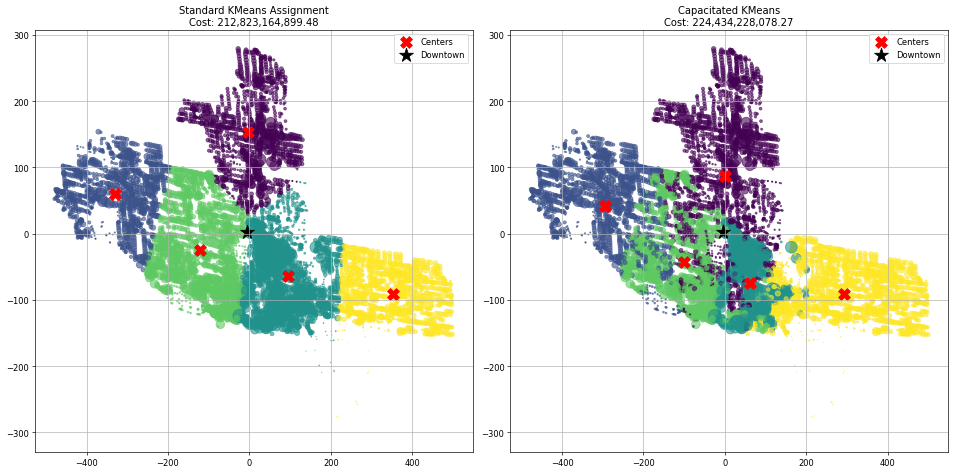

In [53]:
# Visualization on Uploaded Custom Coordinates
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

# Standard KMeans Plot
axes[0].scatter(node_locations_custom[:, 0], node_locations_custom[:, 1], c=k_labels_cust, cmap='viridis', s=node_demands_custom * 0.2, alpha=0.6)
axes[0].scatter(k_centers_cust[:, 0], k_centers_cust[:, 1], c='red', marker='X', s=200, label='Centers')
axes[0].scatter(downtown_custom[0], downtown_custom[1], c='black', marker='*', s=300, label='Downtown')
axes[0].set_title(f'Standard KMeans Assignment\nCost: {k_cost_cust:,.2f}')
axes[0].grid(True)
axes[0].legend()

# Capacitated KMeans Plot
axes[1].scatter(node_locations_custom[:, 0], node_locations_custom[:, 1], c=cap_labels_cust, cmap='viridis', s=node_demands_custom * 0.2, alpha=0.6)
axes[1].scatter(cap_centers_cust[:, 0], cap_centers_cust[:, 1], c='red', marker='X', s=200, label='Centers')
axes[1].scatter(downtown_custom[0], downtown_custom[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f'Capacitated KMeans\nCost: {cap_cost_cust:,.2f}')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

#### Simulated Annealing Location Problem Solver

In [54]:
import numpy as np
import matplotlib.pyplot as plt

def run_simulated_annealing(locations, demands, n_clusters=5, max_cap=229999, initial_temp=1000.0, cooling_rate=0.95, max_iter=200):
    # Initialize with K-Means centroids to start in a reasonable area
    from sklearn.cluster import KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
    current_centers = kmeans.fit(locations).cluster_centers_

    # Helper to assign nodes to current centers with capacity constraints
    def assign_capacitated(centers):
        n_nodes = len(locations)
        labels = -np.ones(n_nodes, dtype=int)
        assigned_demands = np.zeros(n_clusters)
        sorted_indices = np.argsort(demands)[::-1]

        for idx in sorted_indices:
            loc = locations[idx]
            dem = demands[idx]
            dists = np.linalg.norm(centers - loc, axis=1)
            preferred = np.argsort(dists)

            assigned = False
            for c in preferred:
                if assigned_demands[c] + dem <= max_cap:
                    labels[idx] = c
                    assigned_demands[c] += dem
                    assigned = True
                    break
            if not assigned:
                closest = preferred[0]
                labels[idx] = closest
                assigned_demands[closest] += dem
        return labels

    # Initial assignment & cost
    current_labels = assign_capacitated(current_centers)
    current_cost, _ = evaluate_cost_custom(current_centers, current_labels, locations, demands, max_cap)

    best_centers = np.copy(current_centers)
    best_labels = np.copy(current_labels)
    best_cost = current_cost

    temp = initial_temp
    cost_history = [current_cost]

    # Spatial boundary to control perturbation scale
    coord_std = np.std(locations, axis=0) * 0.1

    np.random.seed(42)
    for iteration in range(max_iter):
        # Perturb a random center
        new_centers = np.copy(current_centers)
        target_center_idx = np.random.randint(0, n_clusters)
        perturbation = np.random.normal(0, coord_std)
        new_centers[target_center_idx] += perturbation

        # Re-assign and calculate cost
        new_labels = assign_capacitated(new_centers)
        new_cost, _ = evaluate_cost_custom(new_centers, new_labels, locations, demands, max_cap)

        # Metropolis acceptance criterion
        delta = new_cost - current_cost
        if delta < 0 or np.random.rand() < np.exp(-delta / temp):
            current_centers = new_centers
            current_labels = new_labels
            current_cost = new_cost

            if current_cost < best_cost:
                best_centers = np.copy(current_centers)
                best_labels = np.copy(current_labels)
                best_cost = current_cost

        cost_history.append(current_cost)
        temp *= cooling_rate

    print(f"Simulated Annealing completed. Initial Cost: {cost_history[0]:,.2f} -> Best Cost Found: {best_cost:,.2f}")
    return best_centers, best_labels, cost_history

In [55]:
# Run Simulated Annealing Solver on custom dataset
sa_centers, sa_labels, sa_history = run_simulated_annealing(
    node_locations_custom, node_demands_custom, n_clusters=DC_custom, max_cap=dc_capacity_custom, max_iter=150
)

# Calculate final costs and demands
sa_cost, sa_demands = evaluate_cost_custom(
    sa_centers, sa_labels, node_locations_custom, node_demands_custom, dc_capacity_custom
)
print(f"Final Demands of Simulated Annealing: {sa_demands}")

Simulated Annealing completed. Initial Cost: 266,444,932,298.99 -> Best Cost Found: 171,535,816,836.22
Final Demands of Simulated Annealing: [185498. 204456. 229999. 229999. 150048.]


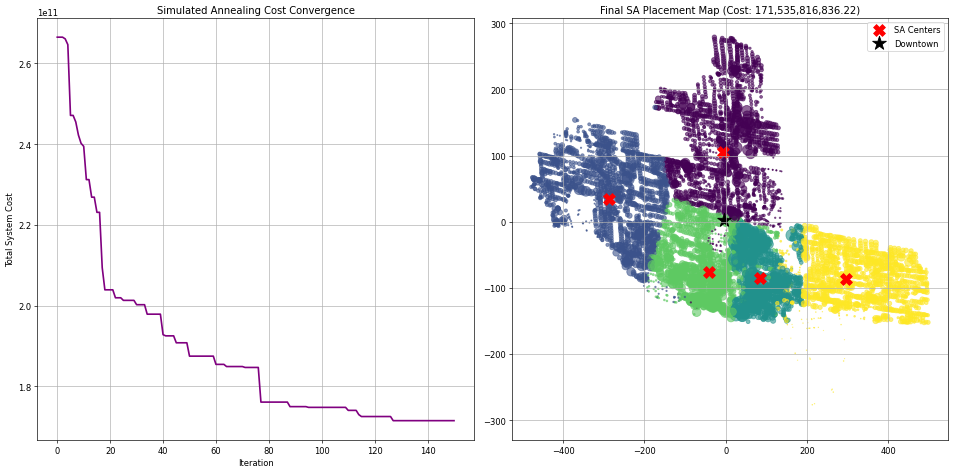

In [56]:
# Plot Simulated Annealing Cost Convergence & Final Placement
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

# Convergence curve
axes[0].plot(sa_history, color='purple', lw=2)
axes[0].set_title("Simulated Annealing Cost Convergence")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("Total System Cost")
axes[0].grid(True)

# Layout map
axes[1].scatter(node_locations_custom[:, 0], node_locations_custom[:, 1], c=sa_labels, cmap='viridis', s=node_demands_custom * 0.2, alpha=0.6)
axes[1].scatter(sa_centers[:, 0], sa_centers[:, 1], c='red', marker='X', s=200, label='SA Centers')
axes[1].scatter(downtown_custom[0], downtown_custom[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f"Final SA Placement Map (Cost: {sa_cost:,.2f})")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

#### Clean Functional Genetic Algorithm V1 Implementation

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# --- 1. Step-by-Step GA Helper Functions ---

def initialize_population(locations, pop_size=30, K=5):
    """Generates initial population of facility locations by perturbing K-Means centroids."""
    kmeans = KMeans(n_clusters=K, random_state=42, n_init='auto')
    base_centers = kmeans.fit(locations).cluster_centers_
    coord_std = np.std(locations, axis=0) * 0.1

    population = []
    for _ in range(pop_size):
        # Perturb slightly to create variations
        individual = base_centers + np.random.normal(0, coord_std, size=base_centers.shape)
        population.append(individual)
    return population

def crossover(parent1, parent2, crossover_rate=0.8):
    """Performs arithmetic crossover on two candidate solutions."""
    if np.random.rand() < crossover_rate:
        alpha = np.random.rand(*parent1.shape)
        child1 = alpha * parent1 + (1 - alpha) * parent2
        child2 = (1 - alpha) * parent1 + alpha * parent2
        return child1, child2
    return parent1.copy(), parent2.copy()

def mutate(individual, mutation_rate=0.15, scale=1.0):
    """Applies Gaussian perturbation to facility coordinates with a given mutation rate."""
    mutated = individual.copy()
    if np.random.rand() < mutation_rate:
        # Mutate coordinates of a random facility
        facility_idx = np.random.randint(0, len(individual))
        mutated[facility_idx] += np.random.normal(0, scale, size=2)
    return mutated

In [68]:
# --- 2. Main Genetic Algorithm Function ---

def genetic_algorithm(data, K, demands, pop_size=30, generations=20, mutation_rate=0.15):
    """Runs the complete procedural Genetic Algorithm for location optimization."""
    np.random.seed(42)
    locations = data[['X', 'Y']].values
    coord_std = np.std(locations, axis=0) * 0.1

    # Generate population
    population = initialize_population(locations, pop_size=pop_size, K=K)

    best_cost = float('inf')
    best_sol = None
    best_labels = None
    cost_history = []

    print(f"Starting GA with {generations} generations...")
    for gen in range(generations):
        # Evaluate fitness for the current generation
        fitnesses = []
        for ind in population:
            # Correctly calculate assignments with integer labels first
            labels, _ = solver_v2.calculate_closest_nodes(ind)
            labels = labels.astype(np.int32)
            cost, _ = evaluate_cost_custom(ind, labels, locations, demands, dc_capacity_custom)
            fitnesses.append(cost)

            if cost < best_cost:
                best_cost = cost
                best_sol = np.copy(ind)
                best_labels = np.copy(labels)

        cost_history.append(best_cost)

        # Build next generation
        new_pop = []
        # Elitism: keep best solution
        new_pop.append(best_sol.copy())

        while len(new_pop) < pop_size:
            # Tournament selection (size = 4)
            sel_idx_1 = np.random.choice(pop_size, size=4, replace=False)
            p1 = population[sel_idx_1[np.argmin([fitnesses[i] for i in sel_idx_1])]]

            sel_idx_2 = np.random.choice(pop_size, size=4, replace=False)
            p2 = population[sel_idx_2[np.argmin([fitnesses[i] for i in sel_idx_2])]]

            # Crossover and Mutation
            child1, child2 = crossover(p1, p2)
            child1 = mutate(child1, mutation_rate=mutation_rate, scale=coord_std)
            child2 = mutate(child2, mutation_rate=mutation_rate, scale=coord_std)

            new_pop.extend([child1, child2])

        population = new_pop[:pop_size]
        print(f"  > Gen {gen+1}/{generations} | Best Cost: {best_cost:,.2f}")

    return best_sol, best_labels, cost_history

Starting GA with 20 generations...
  > Gen 1/20 | Best Cost: 246,437,039,338.11
  > Gen 2/20 | Best Cost: 239,467,034,284.49
  > Gen 3/20 | Best Cost: 232,681,740,954.92
  > Gen 4/20 | Best Cost: 225,379,129,257.91
  > Gen 5/20 | Best Cost: 216,719,266,987.03
  > Gen 6/20 | Best Cost: 216,719,266,987.03
  > Gen 7/20 | Best Cost: 214,889,646,917.57
  > Gen 8/20 | Best Cost: 210,697,047,189.69
  > Gen 9/20 | Best Cost: 207,996,444,130.78
  > Gen 10/20 | Best Cost: 207,931,011,753.13
  > Gen 11/20 | Best Cost: 198,409,776,346.60
  > Gen 12/20 | Best Cost: 198,409,776,346.60
  > Gen 13/20 | Best Cost: 197,568,895,361.44
  > Gen 14/20 | Best Cost: 196,282,028,716.42
  > Gen 15/20 | Best Cost: 195,497,812,060.06
  > Gen 16/20 | Best Cost: 193,938,571,222.59
  > Gen 17/20 | Best Cost: 193,938,571,222.59
  > Gen 18/20 | Best Cost: 191,387,482,138.43
  > Gen 19/20 | Best Cost: 189,552,251,400.63
  > Gen 20/20 | Best Cost: 189,173,267,113.05


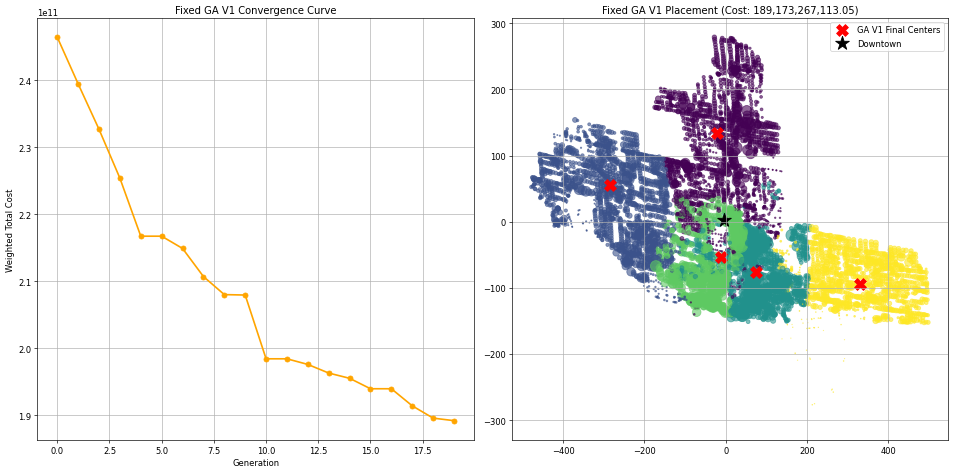

In [69]:
# Re-execute the functional genetic algorithm with the fix applied
best_centers_fixed, best_labels_fixed, history_fixed = genetic_algorithm(
    data=df_custom,
    K=DC_custom,
    demands=node_demands_custom,
    pop_size=30,
    generations=20,
    mutation_rate=0.15
)

# Plot the newly computed correct results
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

axes[0].plot(history_fixed, color='orange', marker='o', lw=2)
axes[0].set_title("Fixed GA V1 Convergence Curve")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Weighted Total Cost")
axes[0].grid(True)

axes[1].scatter(node_locations_custom[:, 0], node_locations_custom[:, 1], c=best_labels_fixed, cmap='viridis', s=node_demands_custom * 0.2, alpha=0.6)
axes[1].scatter(best_centers_fixed[:, 0], best_centers_fixed[:, 1], c='red', marker='X', s=200, label='GA V1 Final Centers')
axes[1].scatter(downtown_custom[0], downtown_custom[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f"Fixed GA V1 Placement (Cost: {history_fixed[-1]:,.2f})")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

#### Adaptive Genetic Algorithm (AGA) Implementation
Here we implement a procedural Adaptive Genetic Algorithm. The crossover rate $P_c$ and mutation rate $P_m$ adjust dynamically for each individual based on its fitness relative to the average fitness ($f_{avg}$) and the best fitness ($f_{min}$ or $f_{best}$) of the current population.

In [70]:
import numpy as np
import matplotlib.pyplot as plt

def get_adaptive_rates(f, f_min, f_avg, pc_max=0.9, pc_min=0.4, pm_max=0.3, pm_min=0.05):
    """Calculates adaptive crossover (pc) and mutation (pm) probabilities.
    For individuals with better (lower) fitness than average, we scale down pc and pm.
    """
    if f_avg == f_min:
        return pc_max, pm_max

    if f <= f_avg:
        # High-fitness individuals (lower cost)
        pc = pc_min + (pc_max - pc_min) * (f - f_min) / (f_avg - f_min)
        pm = pm_min + (pm_max - pm_min) * (f - f_min) / (f_avg - f_min)
    else:
        # Low-fitness individuals (higher cost)
        pc = pc_max
        pm = pm_max

    return pc, pm

def adaptive_crossover(parent1, parent2, f1, f2, f_min, f_avg, pc_max=0.9, pc_min=0.4):
    """Performs arithmetic crossover with an adaptive crossover rate."""
    f_prime = min(f1, f2)
    pc, _ = get_adaptive_rates(f_prime, f_min, f_avg, pc_max=pc_max, pc_min=pc_min)

    if np.random.rand() < pc:
        alpha = np.random.rand(*parent1.shape)
        child1 = alpha * parent1 + (1 - alpha) * parent2
        child2 = (1 - alpha) * parent1 + alpha * parent2
        return child1, child2
    return parent1.copy(), parent2.copy()

def adaptive_mutate(individual, f, f_min, f_avg, pm_max=0.3, pm_min=0.05, scale=1.0):
    """Applies Gaussian mutation with an adaptive mutation rate."""
    _, pm = get_adaptive_rates(f, f_min, f_avg, pm_max=pm_max, pm_min=pm_min)

    mutated = individual.copy()
    if np.random.rand() < pm:
        facility_idx = np.random.randint(0, len(individual))
        mutated[facility_idx] += np.random.normal(0, scale, size=2)
    return mutated

In [71]:
def adaptive_genetic_algorithm(data, K, demands, pop_size=30, generations=20):
    """Runs the procedural Adaptive Genetic Algorithm solver."""
    np.random.seed(42)
    locations = data[['X', 'Y']].values
    coord_std = np.std(locations, axis=0) * 0.1

    # 1. Initialize population
    population = initialize_population(locations, pop_size=pop_size, K=K)

    best_cost = float('inf')
    best_sol = None
    best_labels = None
    cost_history = []

    print(f"Starting Adaptive GA with {generations} generations...")
    for gen in range(generations):
        # Evaluate fitness for the current population
        fitnesses = []
        labels_list = []
        for ind in population:
            labels, _ = solver_v2.calculate_closest_nodes(ind)
            labels = labels.astype(np.int32)
            cost, _ = evaluate_cost_custom(ind, labels, locations, demands, dc_capacity_custom)
            fitnesses.append(cost)
            labels_list.append(labels)

            if cost < best_cost:
                best_cost = cost
                best_sol = np.copy(ind)
                best_labels = np.copy(labels)

        cost_history.append(best_cost)

        f_min = np.min(fitnesses)
        f_avg = np.mean(fitnesses)

        # 2. Rebuild population using Adaptive selection & operators
        new_pop = []
        new_pop.append(best_sol.copy()) # Elitism

        while len(new_pop) < pop_size:
            # Tournament selection (size = 4)
            sel_idx_1 = np.random.choice(pop_size, size=4, replace=False)
            best_idx_1 = sel_idx_1[np.argmin([fitnesses[i] for i in sel_idx_1])]
            p1, f1 = population[best_idx_1], fitnesses[best_idx_1]

            sel_idx_2 = np.random.choice(pop_size, size=4, replace=False)
            best_idx_2 = sel_idx_2[np.argmin([fitnesses[i] for i in sel_idx_2])]
            p2, f2 = population[best_idx_2], fitnesses[best_idx_2]

            # Adaptive Crossover & Mutation
            child1, child2 = adaptive_crossover(p1, p2, f1, f2, f_min, f_avg)
            child1 = adaptive_mutate(child1, f1, f_min, f_avg, scale=coord_std)
            child2 = adaptive_mutate(child2, f2, f_min, f_avg, scale=coord_std)

            new_pop.extend([child1, child2])

        population = new_pop[:pop_size]
        print(f"  > Gen {gen+1}/{generations} | Best Cost: {best_cost:,.2f} | Avg Cost: {f_avg:,.2f}")

    return best_sol, best_labels, cost_history

Starting Adaptive GA with 20 generations...
  > Gen 1/20 | Best Cost: 246,437,039,338.11 | Avg Cost: 273,780,954,047.38
  > Gen 2/20 | Best Cost: 243,196,057,316.19 | Avg Cost: 254,522,191,546.30
  > Gen 3/20 | Best Cost: 235,340,422,181.04 | Avg Cost: 245,761,609,328.21
  > Gen 4/20 | Best Cost: 232,078,844,615.23 | Avg Cost: 240,733,240,591.54
  > Gen 5/20 | Best Cost: 229,208,496,475.64 | Avg Cost: 236,195,258,220.13
  > Gen 6/20 | Best Cost: 229,208,496,475.64 | Avg Cost: 231,659,272,819.47
  > Gen 7/20 | Best Cost: 222,989,413,259.90 | Avg Cost: 229,829,427,841.52
  > Gen 8/20 | Best Cost: 217,782,790,370.86 | Avg Cost: 226,655,837,105.35
  > Gen 9/20 | Best Cost: 210,147,766,989.08 | Avg Cost: 222,429,727,543.02
  > Gen 10/20 | Best Cost: 210,147,766,989.08 | Avg Cost: 219,344,075,309.87
  > Gen 11/20 | Best Cost: 210,147,766,989.08 | Avg Cost: 214,073,909,765.56
  > Gen 12/20 | Best Cost: 207,326,968,615.86 | Avg Cost: 211,704,304,800.19
  > Gen 13/20 | Best Cost: 205,391,004,30

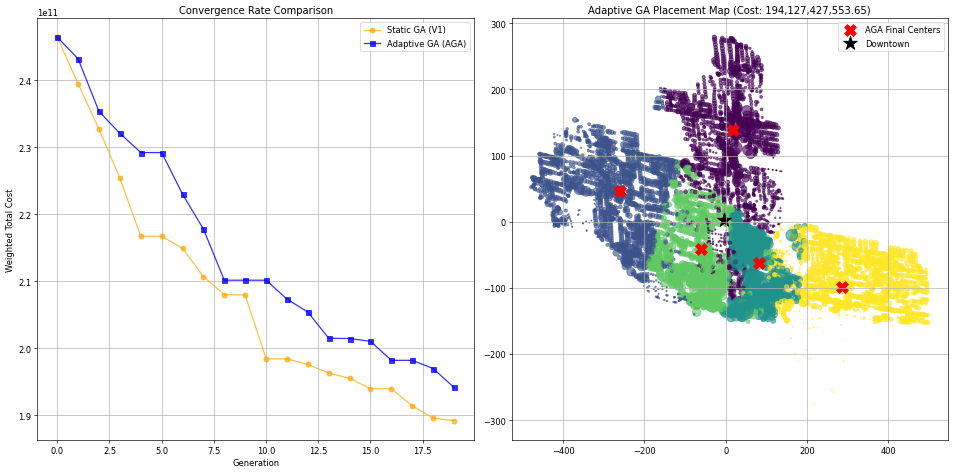

In [72]:
# Execute Adaptive Genetic Algorithm
best_centers_aga, best_labels_aga, history_aga = adaptive_genetic_algorithm(
    data=df_custom,
    K=DC_custom,
    demands=node_demands_custom,
    pop_size=30,
    generations=20
)

# Plot the comparative results
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

axes[0].plot(history_fixed, color='orange', marker='o', label='Static GA (V1)', alpha=0.7)
axes[0].plot(history_aga, color='blue', marker='s', label='Adaptive GA (AGA)', alpha=0.8)
axes[0].set_title("Convergence Rate Comparison")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Weighted Total Cost")
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(node_locations_custom[:, 0], node_locations_custom[:, 1], c=best_labels_aga, cmap='viridis', s=node_demands_custom * 0.2, alpha=0.6)
axes[1].scatter(best_centers_aga[:, 0], best_centers_aga[:, 1], c='red', marker='X', s=200, label='AGA Final Centers')
axes[1].scatter(downtown_custom[0], downtown_custom[1], c='black', marker='*', s=300, label='Downtown')
axes[1].set_title(f"Adaptive GA Placement Map (Cost: {history_aga[-1]:,.2f})")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

#### Simulated Annealing Location Problem Solver V2

Here we define a class-based, modular Simulated Annealing Solver containing the full mathematical cost evaluations, exponential scheduling routines, local neighbor perturbations, and plotting mechanisms.

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

class SimulatedAnnealingSolverV2:
    def __init__(self, nodes_info, total_deliveries, facility_capacity,
                 facility_cost=0.0, facility_increase_prob=0.1, facility_decrease_prob=0.1,
                 num_neighbors=1, num_iterations=150, k=20.0, lam=0.005):
        self.nodes_info = nodes_info
        self.locations = nodes_info[['X', 'Y']].values
        self.demands = nodes_info['Number Deliveries'].values
        self.total_deliveries = total_deliveries
        self.facility_capacity = facility_capacity
        self.facility_cost = facility_cost
        self.facility_increase_prob = facility_increase_prob
        self.facility_decrease_prob = facility_decrease_prob
        self.num_neighbors = num_neighbors
        self.num_iterations = num_iterations
        self.k = k
        self.lam = lam

        # Internal variables derived dynamically
        self.downtown = self.locations.mean(axis=0)
        self.dists_to_downtown = np.linalg.norm(self.locations - self.downtown, axis=1)
        self.dist_max = self.dists_to_downtown.max()
        self.dist_min = self.dists_to_downtown.min()
        self.min_bid_factor = 0.2

        # Best run results storage
        self.best_solution = None
        self.best_labels = None
        self.best_cost = float('inf')
        self.cost_history = []

    def calculate_closest_nodes(self, solution):
        """Assign nodes to facility locations with capacity constraints."""
        n_nodes = len(self.locations)
        n_facilities = len(solution)
        labels = -np.ones(n_nodes, dtype=int)
        assigned_demands = np.zeros(n_facilities)

        # Sort nodes by demand descending
        sorted_indices = np.argsort(self.demands)[::-1]

        for idx in sorted_indices:
            loc = self.locations[idx]
            dem = self.demands[idx]
            dists = np.linalg.norm(solution - loc, axis=1)
            preferred = np.argsort(dists)

            assigned = False
            for f_idx in preferred:
                if assigned_demands[f_idx] + dem <= self.facility_capacity:
                    labels[idx] = f_idx
                    assigned_demands[f_idx] += dem
                    assigned = True
                    break
            if not assigned:
                closest = preferred[0]
                labels[idx] = closest
                assigned_demands[closest] += dem
        return labels, assigned_demands

    def calculate_facility_cost(self, facility_closest_nodes):
        """Compute costs of assignments for each facility."""
        # Handled in unified cost_function for vectorized compute speed
        pass

    def facility_placement_cost(self, facility_id):
        """Any baseline fixed deployment costs for facilities."""
        return self.facility_cost

    def cost_function(self, solution):
        """Unified Custom Evaluation matching system mathematical equations."""
        labels, assigned_demands = self.calculate_closest_nodes(solution)
        n_facilities = len(solution)
        total_cost = 0.0

        for f_idx in range(n_facilities):
            tot_demand = assigned_demands[f_idx]
            pen_od = 1.5 if tot_demand > self.facility_capacity else 1.0

            # Beta calculation based on distance to downtown
            dist_dtwn = np.linalg.norm(solution[f_idx] - self.downtown)
            beta = 1.0 - self.min_bid_factor * (dist_dtwn / (self.dist_max - self.dist_min))

            assigned_mask = (labels == f_idx)
            if np.any(assigned_mask):
                coords = self.locations[assigned_mask]
                dems = self.demands[assigned_mask]
                dists_sq = np.sum((coords - solution[f_idx]) ** 2, axis=1)
                weighted_sum = np.sum(dists_sq * dems)
                total_cost += pen_od * beta * weighted_sum

            total_cost += self.facility_placement_cost(f_idx)

        final_cost = total_cost * (n_facilities ** 2)
        return final_cost, labels

    def gen_random_solution(self):
        """Generate a base starting configuration using standard KMeans partitions."""
        kmeans = KMeans(n_clusters=5, random_state=42, n_init='auto')
        return kmeans.fit(self.locations).cluster_centers_

    def exponential_scheduling(self, step):
        """Temperature cooling calculation according to scheduling parameters."""
        return self.k * np.exp(-self.lam * step)

    def neighbour_function(self, solution):
        """Perturbs current center locations randomly proportional to spatial spread."""
        new_solution = np.copy(solution)
        coord_std = np.std(self.locations, axis=0) * 0.1
        target_center = np.random.randint(0, len(solution))
        new_solution[target_center] += np.random.normal(0, coord_std)
        return new_solution

    def initialize(self):
        """Prepares initial configuration state."""
        initial_sol = self.gen_random_solution()
        initial_cost, initial_labels = self.cost_function(initial_sol)

        self.best_solution = np.copy(initial_sol)
        self.best_labels = np.copy(initial_labels)
        self.best_cost = initial_cost
        self.cost_history = [initial_cost]
        return initial_sol, initial_cost, initial_labels

    def solve(self):
        """Solves the location placement task using Simulated Annealing V2."""
        current_sol, current_cost, current_labels = self.initialize()

        np.random.seed(42)
        for step in range(self.num_iterations):
            temp = self.exponential_scheduling(step)
            candidate_sol = self.neighbour_function(current_sol)
            candidate_cost, candidate_labels = self.cost_function(candidate_sol)

            delta = candidate_cost - current_cost
            if delta < 0 or np.random.rand() < np.exp(-delta / temp):
                current_sol = candidate_sol
                current_cost = candidate_cost
                current_labels = candidate_labels

                if current_cost < self.best_cost:
                    self.best_solution = np.copy(current_sol)
                    self.best_labels = np.copy(current_labels)
                    self.best_cost = current_cost

            self.cost_history.append(current_cost)

        print(f"Solver V2 completed. Initial: {self.cost_history[0]:,.2f} -> Best: {self.best_cost:,.2f}")
        return self.best_solution, self.best_cost

    def visualize_solution(self):
        """Plot convergence sequence and optimized geographical layout side-by-side."""
        fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

        axes[0].plot(self.cost_history, color='navy', lw=2)
        axes[0].set_title("Solver V2 Cost Convergence")
        axes[0].set_xlabel("Iteration Step")
        axes[0].set_ylabel("Weighted Total Cost")
        axes[0].grid(True)

        axes[1].scatter(self.locations[:, 0], self.locations[:, 1], c=self.best_labels, cmap='viridis', s=self.demands * 0.2, alpha=0.6)
        axes[1].scatter(self.best_solution[:, 0], self.best_solution[:, 1], c='red', marker='X', s=200, label='Optimized Centers')
        axes[1].scatter(self.downtown[0], self.downtown[1], c='black', marker='*', s=300, label='Downtown')
        axes[1].set_title(f"V2 Final Distribution Map (Cost: {self.best_cost:,.2f})")
        axes[1].grid(True)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

Solver V2 completed. Initial: 266,444,932,298.99 -> Best: 192,387,226,986.55


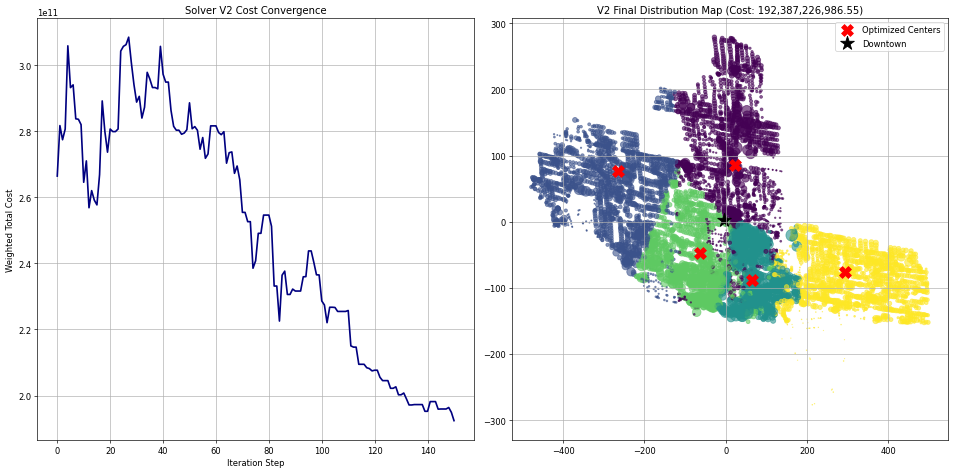

In [59]:
# Instantiating and running the newly constructed Solver V2 class
solver_v2 = SimulatedAnnealingSolverV2(
    nodes_info=df_custom,
    total_deliveries=total_demand_custom,
    facility_capacity=dc_capacity_custom,
    k=1e11,          # Scale temperature constant matching custom dataset cost dimensions
    lam=0.03,
    num_iterations=150
)

best_sol_centers, best_sol_cost = solver_v2.solve()
solver_v2.visualize_solution()

#### Genetic Algorithm Location Problem Solver (V2)

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

class GeneticAlgorithmSolverV2:
    def __init__(self, nodes_info, total_deliveries, facility_capacity,
                 facility_cost=0.0, population_size=30, generations=100,
                 crossover_rate=0.8, mutation_rate=0.2, tournament_size=5):
        self.nodes_info = nodes_info
        self.locations = nodes_info[['X', 'Y']].values
        self.demands = nodes_info['Number Deliveries'].values
        self.total_deliveries = total_deliveries
        self.facility_capacity = facility_capacity
        self.facility_cost = facility_cost

        self.pop_size = population_size
        self.generations = generations
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.tournament_size = tournament_size

        # Spatial parameters derived dynamically
        self.downtown = self.locations.mean(axis=0)
        self.dists_to_downtown = np.linalg.norm(self.locations - self.downtown, axis=1)
        self.dist_max = self.dists_to_downtown.max()
        self.dist_min = self.dists_to_downtown.min()
        self.min_bid_factor = 0.2
        self.coord_std = np.std(self.locations, axis=0) * 0.1

        self.best_solution = None
        self.best_labels = None
        self.best_cost = float('inf')
        self.cost_history = []

    def calculate_closest_nodes(self, solution):
        """Assign nodes to facility locations with capacity constraints."""
        n_nodes = len(self.locations)
        n_facilities = len(solution)
        labels = -np.ones(n_nodes, dtype=int)
        assigned_demands = np.zeros(n_facilities)
        sorted_indices = np.argsort(self.demands)[::-1]

        for idx in sorted_indices:
            loc = self.locations[idx]
            dem = self.demands[idx]
            dists = np.linalg.norm(solution - loc, axis=1)
            preferred = np.argsort(dists)

            assigned = False
            for f_idx in preferred:
                if assigned_demands[f_idx] + dem <= self.facility_capacity:
                    labels[idx] = f_idx
                    assigned_demands[f_idx] += dem
                    assigned = True
                    break
            if not assigned:
                closest = preferred[0]
                labels[idx] = closest
                assigned_demands[closest] += dem
        return labels, assigned_demands

    def facility_placement_cost(self, facility_id):
        return self.facility_cost

    def cost_function(self, solution):
        """Evaluate system total cost using coordinate points."""
        labels, assigned_demands = self.calculate_closest_nodes(solution)
        n_facilities = len(solution)
        total_cost = 0.0

        for f_idx in range(n_facilities):
            tot_demand = assigned_demands[f_idx]
            pen_od = 1.5 if tot_demand > self.facility_capacity else 1.0
            dist_dtwn = np.linalg.norm(solution[f_idx] - self.downtown)
            beta = 1.0 - self.min_bid_factor * (dist_dtwn / (self.dist_max - self.dist_min))

            assigned_mask = (labels == f_idx)
            if np.any(assigned_mask):
                coords = self.locations[assigned_mask]
                dems = self.demands[assigned_mask]
                dists_sq = np.sum((coords - solution[f_idx]) ** 2, axis=1)
                weighted_sum = np.sum(dists_sq * dems)
                total_cost += pen_od * beta * weighted_sum

            total_cost += self.facility_placement_cost(f_idx)

        return total_cost * (n_facilities ** 2), labels

    def gen_random_solution(self):
        """Generate randomized perturbed coordinates around standard centroids."""
        kmeans = KMeans(n_clusters=5, random_state=42, n_init='auto')
        base_centers = kmeans.fit(self.locations).cluster_centers_
        perturbed_centers = base_centers + np.random.normal(0, self.coord_std, size=base_centers.shape)
        return perturbed_centers

    def select_parent(self, population, fitnesses):
        """Tournament Selection."""
        idx = np.random.choice(len(population), size=self.tournament_size, replace=False)
        selected_fitness = [fitnesses[i] for i in idx]
        best_idx = idx[np.argmin(selected_fitness)]
        return population[best_idx]

    def crossover(self, parent1, parent2):
        """Arithmetic Crossover of spatial centroids."""
        if np.random.rand() < self.crossover_rate:
            alpha = np.random.rand(*parent1.shape)
            child1 = alpha * parent1 + (1 - alpha) * parent2
            child2 = (1 - alpha) * parent1 + alpha * parent2
            return child1, child2
        return parent1.copy(), parent2.copy()

    def mutate(self, solution):
        """Gaussian spatial perturbation of coordinates."""
        mutated = solution.copy()
        if np.random.rand() < self.mutation_rate:
            target_idx = np.random.randint(0, len(solution))
            mutated[target_idx] += np.random.normal(0, self.coord_std)
        return mutated

    def solve(self):
        """Optimize facility placements using a Genetic Algorithm (V2)."""
        np.random.seed(42)

        # 1. Initialize population
        population = [self.gen_random_solution() for _ in range(self.pop_size)]

        for generation in range(self.generations):
            # Evaluate fitness of each chromosome
            fitnesses = []
            for ind in population:
                cost, _ = self.cost_function(ind)
                fitnesses.append(cost)

            # Save best candidate globally
            min_fit_idx = np.argmin(fitnesses)
            if fitnesses[min_fit_idx] < self.best_cost:
                self.best_cost = fitnesses[min_fit_idx]
                self.best_solution = np.copy(population[min_fit_idx])
                _, self.best_labels = self.cost_function(self.best_solution)

            self.cost_history.append(self.best_cost)

            # Create next generation
            new_population = []
            while len(new_population) < self.pop_size:
                parent1 = self.select_parent(population, fitnesses)
                parent2 = self.select_parent(population, fitnesses)

                child1, child2 = self.crossover(parent1, parent2)
                child1 = self.mutate(child1)
                child2 = self.mutate(child2)

                new_population.extend([child1, child2])

            population = new_population[:self.pop_size]

            if (generation + 1) % 20 == 0 or generation == 0:
                print(f"Generation {generation+1}/{self.generations} - Current Best Cost: {self.best_cost:,.2f}")

        return self.best_solution, self.best_cost

    def visualize_solution(self):
        fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=60)

        axes[0].plot(self.cost_history, color='teal', lw=2)
        axes[0].set_title("Genetic Algorithm V2 Cost Convergence")
        axes[0].set_xlabel("Generation")
        axes[0].set_ylabel("Weighted Total Cost")
        axes[0].grid(True)

        axes[1].scatter(self.locations[:, 0], self.locations[:, 1], c=self.best_labels, cmap='viridis', s=self.demands * 0.2, alpha=0.6)
        axes[1].scatter(self.best_solution[:, 0], self.best_solution[:, 1], c='red', marker='X', s=200, label='GA Centers')
        axes[1].scatter(self.downtown[0], self.downtown[1], c='black', marker='*', s=300, label='Downtown')
        axes[1].set_title(f"GA V2 Final Distribution Map (Cost: {self.best_cost:,.2f})")
        axes[1].grid(True)

        plt.tight_layout()
        plt.show()

Generation 1/120 - Current Best Cost: 246,437,039,338.11
Generation 20/120 - Current Best Cost: 181,934,841,639.03
Generation 40/120 - Current Best Cost: 175,271,086,842.02
Generation 60/120 - Current Best Cost: 168,240,140,158.13
Generation 80/120 - Current Best Cost: 167,031,294,023.31
Generation 100/120 - Current Best Cost: 166,489,244,592.14
Generation 120/120 - Current Best Cost: 166,489,244,592.14


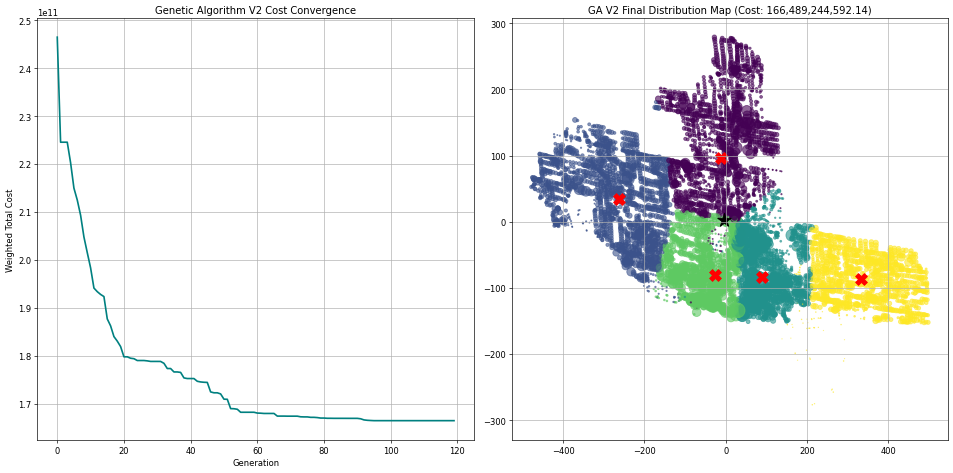

In [63]:
# Instantiate, execute, and visualize the completed Genetic Algorithm Solver V2
ga_solver = GeneticAlgorithmSolverV2(
    nodes_info=df_custom,
    total_deliveries=total_demand_custom,
    facility_capacity=dc_capacity_custom,
    population_size=30,
    generations=120
)

best_ga_centers, best_ga_cost = ga_solver.solve()
ga_solver.visualize_solution()